In [ ]:
import gpxpy
import pandas as pd
import numpy as np

We extract data from `gpx` files Lofoten Skyrace has provided. At the core the `gpx` files contains coordinates and elevation. The files also contain some data about cadence, power and heart rate, but we will not use it as it might be noisy and inaccurate. Instead we use formulas for heart rate and energy consumption from research articles.

In [ ]:
NS = 'http://www.garmin.com/xmlschemas/TrackPointExtension/v1'

with open('32km_Hoka_Lofoten_Skyrace_2025.gpx', 'r') as f:
    gpx = gpxpy.parse(f)

def extract_extensions(p):
    power = hr = cad = None
    for e in p.extensions:
        if e.tag == 'power':
            power = int(e.text) if e.text else None
        elif e.tag == f'{{{NS}}}TrackPointExtension':
            hr_el = e.find(f'{{{NS}}}hr')
            cad_el = e.find(f'{{{NS}}}cad')
            if hr_el is not None:
                hr = int(hr_el.text)
            if cad_el is not None:
                cad = int(cad_el.text)
    return power, hr, cad

points = []
for track in gpx.tracks:
    for segment in track.segments:
        for p in segment.points:
            power, hr, cad = extract_extensions(p)
            points.append({
                'time': p.time,
                'latitude': p.latitude,
                'longitude': p.longitude,
                'elevation': p.elevation,
                'power': power,
                'hr': hr,
                'cad': cad,
            })

df = pd.DataFrame(points)
print(df.head())


                       time   latitude  longitude  elevation  power  hr  cad
0 2025-06-27 16:41:37+00:00  68.232179  14.563808        2.2      0  70    0
1 2025-06-27 16:41:38+00:00  68.232173  14.563800        2.2      0  70    0
2 2025-06-27 16:41:39+00:00  68.232199  14.563803        2.2      0  70    0
3 2025-06-27 16:41:40+00:00  68.232222  14.563824        2.4      0  72    0
4 2025-06-27 16:41:41+00:00  68.232240  14.563838        2.4      0  74    0


## Problem Setup

We formulate the problem of running an optimal marathon as a Markov Decsion Problem (MDP). 

### State
We define the state as:
$S_t = (d_t, e_t, rd_t, re_t, r_t, c_t)$ where 
- $d_t \in \mathbb{R}$ is the distance between the current point $t$ and the next point at time $t + 1$. Since the points are very close, we use the Euclidean distance instead of Haversine formula.
- $e_t \in \mathbb{R}$ is the elevation between the current point $t$ and the next point at time $t + 1$. 
- $rd_t \in \mathbb{R}$ is the remaining distance at time $t$.
- $re_t \in \mathbb{R}$ is the remaining elevation at time $t$.
- $h_t \in \mathbb{R}$ is the heart rate at time $t$.
- $c_t \in \mathbb{R}$ is the calorie surplus at tim $t$ this variable start at some $c_0$ depending on how well we have carb loaded. Negative values mean we are in calorie deficit.
- $T_t \in \mathbb{R}$ is the total time elapsed.
- $D_t \in \mathbb{R}$ is the total distance since start.

A couple of things to notice:
- We can have forward looking state variables as we know the exact route ahead of time. 
- All of these variables fall within some range we discretized to make the problem discrete. However, for this problem we treat them as continuous on the real line.
- All indices $t$ refer to the index of time, not the actual time elapsed since start.


### Action
We define the action space as:
$ A_t = (v_t, i_t)$ 
where
- $v_t \in \{0.0, 0.2, \dots, 20.0\}$ is the velocity to maintain between the current point $t$ and the next point $t + 1$. Notice that we discretiz the action space. This is because we want to use DQN. 
- $i_t \in \{0, 1\}$ is an indicator of whether to eat at time $t$. We assume that eating gives you a fixed amount of calories (this is slighly inaccurate, see [reward section](### Reward Function) for more details on this).


### Transition Probabilies
In this setup we treat all variables as deterministic. An obvious extension is to add uncertainties to formulas to make the problem probabilistic. 
$(S_t, A_t) \to S_{t+1} = (d_{t+1}, e_{t+1}, rd_{t+1}, re_{t+1}, f_h(d_t, e_t, , v_t), c_t - f_c(d_t, e_t) + 10A_t)$
Where
- $f_h$ is a function that takes in a heartrate and a velocity and outputs a new heartrate.
- $f_c$ is a cost function that takes in distance and elevation in the previous step and outputs the cost in terms of calories.
- We also assume you get 10 calories if you decide to eat.


### Reward Function
The reward function consist of a few different components. We want the reward function to at least consider the following:
- Too high heart rate should be penalized. In a more realistic setting we would rather have that a too high heart rate over a certain time period and not necesserialy at an instant. However, this would make the state space much bigger as you would need to make previous times a part of the current state.
- Too big calorie deficit should be penalized. This should be a function that becomes increasingly worse as you deplete your glycogen stores. Indeed, [@Holloszy1996] find that even in "fight or flight" situations, individuals whose muscles are glycogen depleted are unable to either run or fight.
- Eating gives you less calories when you have higher heart rate. A formula for this was hard to find, so we will just use one that makes sense. Even with lower heart rate there are phyiscal limits to what your body can absorb [@Jeukendrup2014]. 
- Not making cutoff times should be penalized heavily. 
- Finishing faster should be rewarded.


$$
R(S_t, S_{t+1}) = \gamma_1R_c(c_t) + \gamma_2R_t(d_t) + \gamma_3R_h(h_t)
$$

Each of the terms in the formula above are explained in greater detail below. Each $\gamma_i$ is a scaling factor so we can scale each contributin term appropriately. 
The reward for calories is a simple formula that penalizes eating too much and too little. The penality is squared to penalize far from $0$ heavily as a serious calorie deficit and surplus is detrimental.
$$
R_c(S_t, A_t) = (\chi_{\{c_{t+1} \geq 200\}}c_{t+1}^2 + \chi_{\{c_{t+1} \leq 200\}}c_{t+1}^2)
$$
Where $\chi$ is the indicator function.

There are four cutoffs for the 32km distance:
- 9km within 3h
- 16km within 5h
- 24km within 7h
- 32km within 9h
$$
R_t(T_t, D_t) = - \infty (\chi_{\{T_t \geq 3\text{h}, D_t \leq 9\text{km}\}} + \chi_{\{T_t \geq 5\text{h}, D_t \leq 16\text{km}\}} + \chi_{\{T_t \geq 7\text{h}, D_t \leq 24\text{km}\}} + \chi_{\{T_t \geq 9\text{h}, D_t \leq 32\text{km}\}}) - T_t
$$
The first four terms represents cutoff and the last is a linear reward incentivizing finishing faster. The scaling $\gamma_2$ will only really affect the last term as the other terms are either $0$ or $\infty$.

For the heartrate you are penalized with a square term up to some $h_{\text{max}}$. Beyond that you are penalized infinitely to basically make this a hard constraint.
$$
R_h(h_t) = -\chi_{\{h_t \geq h_\text{max}\}} \infty - h_t^2
$$



### MDP Formulation
Our goal is to find a policy $\pi$ that maximizes the reward.

$$
\pi^* = \argmax{}
$$

Since we care about finish times and , we set the discount rate $\gamma = 1.0$. We can do this since this is a finite horizon time problem.


Before we can define the states we need to define a few variables first.

We define the following variables:
- $\text{dlat}$ is the difference in latitude between two points
- $\text{dlon}$ is the difference in longitude between two points
- $\text{dx}$ is the horizontal distance between two points. 
- $\text{dy}$ it the vertical distance between two points. 



In [ ]:
# Global Params
h_max = ...
vo2_max = ...
weight = ...

In [ ]:
# Adding state variables
df['dlat'] = df['latitude'].shift(-1) - df['latitude']
df['dlon'] = df['longitude'].shift(-1) - df['longitude']
df['dx'] = (df['dlat']**2 + df['dlon']**2)**(1/2)
df['dy'] = df['elevation'].shift(-1) - df['elevation']

total_elevation = df.loc[df['dy'] >= 0, 'dy'].sum()
df['re'] = total_elevation - df.loc[df['dy'] >= 0, 'dy'].cumsum()


display(df)

,time,latitude,longitude,elevation,power,hr,cad,d_el,re
0,2025-06-27 16:41:37+00:00,68.232179,14.563808,2.2,0,70,0,0.0,2.069800e+03
1,2025-06-27 16:41:38+00:00,68.232173,14.563800,2.2,0,70,0,0.0,2.069800e+03
2,2025-06-27 16:41:39+00:00,68.232199,14.563803,2.2,0,70,0,0.2,2.069600e+03
3,2025-06-27 16:41:40+00:00,68.232222,14.563824,2.4,0,72,0,0.0,2.069600e+03
4,2025-06-27 16:41:41+00:00,68.232240,14.563838,2.4,0,74,0,0.0,2.069600e+03
...,...,...,...,...,...,...,...,...,...
18317,2025-06-27 21:46:54+00:00,68.230251,14.562484,4.0,332,139,76,-0.2,NaN
18318,2025-06-27 21:46:55+00:00,68.230240,14.562551,3.8,333,138,77,0.0,-1.714398e-10
18319,2025-06-27 21:46:56+00:00,68.230229,14.562625,3.8,330,138,77,0.0,-1.714398e-10
18320,2025-06-27 21:46:57+00:00,68.230224,14.562673,3.8,322,139,78,0.0,-1.714398e-10


In [ ]:
# Action space
v = np.linspace(0, 20, 100)
i = np.array([0, 1])

# State space


In [ ]:
def cost_of_running(inc: float):
    return 155.4*inc**5 - 30.4*inc**4 - 43.4*inc**3 + 46.3*inc**2 + 19.5*i + 3.6

def cost_of_walking(inc: float):
    return 280.5*inc**5 - 58.7*inc**4 - 76.8*inc**3 + 51.9*inc**2 + 19.6*i + 2.5



In [ ]:
def reward_function()

In [ ]:
display(df.shape)
display(df.dtypes)
display(df.isna().sum())

(18322, 7)

time         datetime64[us, SimpleTZ('Z')]
latitude                           float64
longitude                          float64
elevation                          float64
power                                int64
hr                                   int64
cad                                  int64
dtype: object

time         0
latitude     0
longitude    0
elevation    0
power        0
hr           0
cad          0
dtype: int64

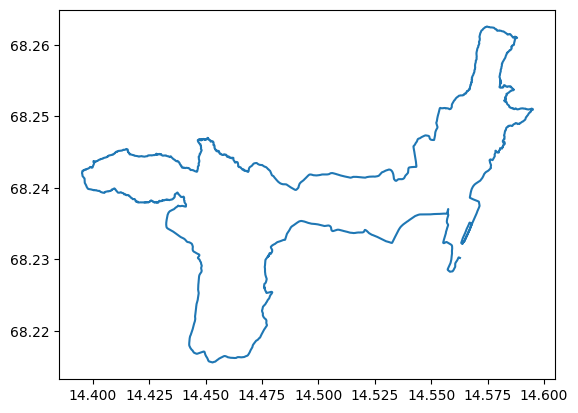

In [ ]:
import matplotlib.pyplot as plt
plt.plot(df['longitude'], df['latitude'])
plt.show()

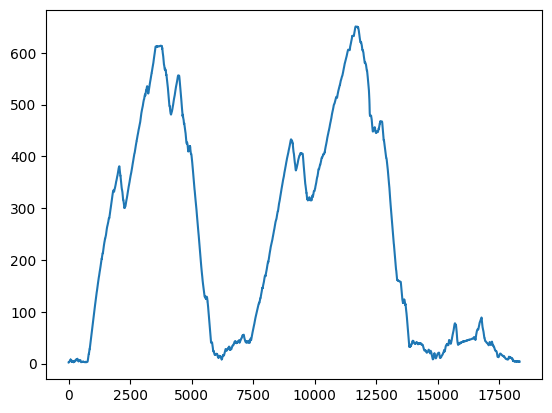

In [ ]:
plt.plot(df.index, df.elevation)
plt.show()

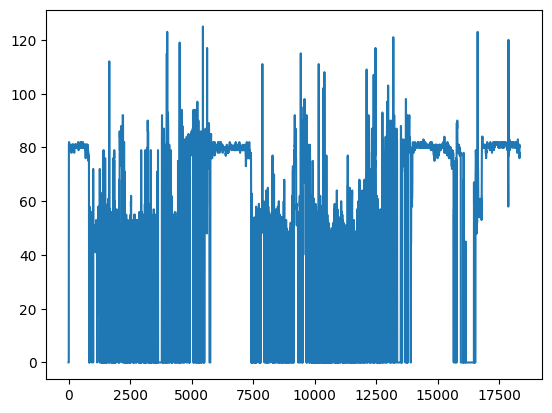

In [ ]:
plt.plot(df.index, df.cad)
plt.show()

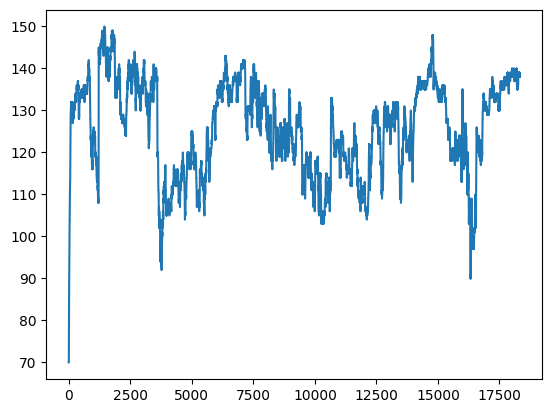

In [ ]:
plt.plot(df.index, df.hr)
plt.show()

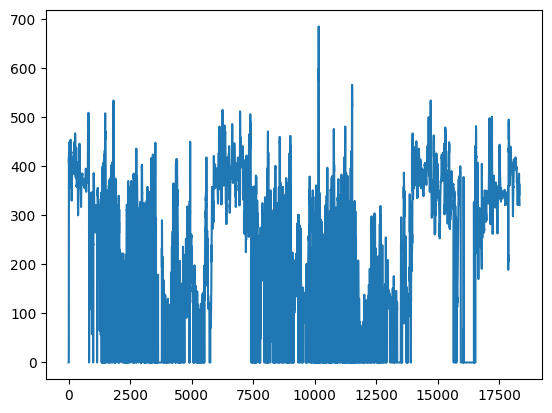

In [ ]:
plt.plot(df.index, df.power)
plt.show()

## References